**Импорты**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV

from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

**Предобработка данных**

In [2]:
df = pd.read_csv('/content/AI4I 2020 Predictive Maintenance Dataset.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [4]:
df = df.drop(['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'], axis=1)
df

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,M,298.8,308.4,1604,29.5,14,0
9996,H,298.9,308.4,1632,31.8,17,0
9997,M,299.0,308.6,1645,33.4,22,0
9998,H,299.0,308.7,1408,48.5,25,0


In [5]:
encoder = OrdinalEncoder(categories=[['L', 'M', 'H']])
df['Type'] = encoder.fit_transform(df[['Type']])
df

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,1.0,298.1,308.6,1551,42.8,0,0
1,0.0,298.2,308.7,1408,46.3,3,0
2,0.0,298.1,308.5,1498,49.4,5,0
3,0.0,298.2,308.6,1433,39.5,7,0
4,0.0,298.2,308.7,1408,40.0,9,0
...,...,...,...,...,...,...,...
9995,1.0,298.8,308.4,1604,29.5,14,0
9996,2.0,298.9,308.4,1632,31.8,17,0
9997,1.0,299.0,308.6,1645,33.4,22,0
9998,2.0,299.0,308.7,1408,48.5,25,0


In [6]:
df['Machine failure'].value_counts()

,count
Machine failure,
0,9661
1,339


In [7]:
X = df.drop(['Machine failure'], axis=1)
y = df['Machine failure']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

**Бейзлайн**

In [8]:
X_train_scaler = StandardScaler().fit_transform(X_train)

baseline = LogisticRegression(random_state=42)
cv_scores = cross_val_score(baseline, X_train_scaler, y_train, cv=5, scoring='roc_auc')
print(f'Средний ROC-AUC на кросс-валидации {cv_scores.mean()}')

Средний ROC-AUC на кросс-валидации 0.8946563377614508


**Обучение и подбор гиперпараметров**

In [9]:
params = {'n_estimators' : [50, 100, 150, 200],
          'max_depth' : [4, 6, 8, None],
          'min_samples_split' : [2, 5, 10],
          'min_samples_leaf' : [1, 2, 4]}

rf = RandomForestClassifier(random_state=42)

search = RandomizedSearchCV(rf, param_distributions=params, n_iter=10, scoring='roc_auc', cv=5, random_state=42, n_jobs=1)
search.fit(X_train, y_train)

best_rf = search.best_estimator_
print(f'Лучшие параметры {search.best_params_}')
print(f'ROC-AUC на кросс-валидации {search.best_score_}')
print(f'Прирост по сравнению с бейзлайном: +{(search.best_score_ - cv_scores.mean())}')

Лучшие параметры {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 8}
ROC-AUC на кросс-валидации 0.9755979567758791
Прирост по сравнению с бейзлайном: +0.08094161901442831


**Результаты на тестовой выборке и анализ важности признаков**

In [10]:
y_pred = best_rf.predict(X_test)
y_pred_proba = best_rf.predict_proba(X_test)[:, 1]

test_roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f'ROC-AUC на тесте: {test_roc_auc}')


ROC-AUC на тесте: 0.9662571550359275


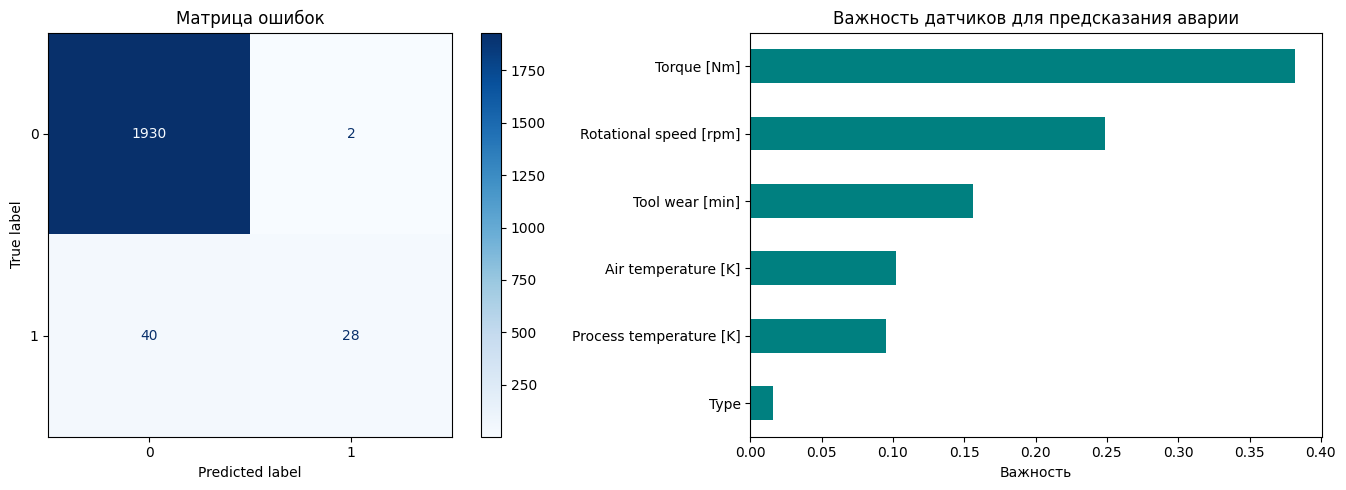

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues')
axes[0].set_title("Матрица ошибок")

importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Важность датчиков для предсказания аварии")
axes[1].set_xlabel("Важность")

plt.tight_layout()
plt.show()